# Controlled representation comparison on the Zhang 2021 atlas

Reads tables from `../data/` and writes figures to `../output/`.
Source analysis: `../../NOTEBOOK_PROVENANCE.tsv`.

The reviewer asked for a controlled comparison on identical cells and
identical fragments per cell: side-by-side UMAPs plus clustering/separation
metrics for LEAF-1, coordinate/bin representations, and the dataset's own
established scATAC pipeline. Every representation in a set is built from the same
10,131 cells, so the only variable is the representation. Two sets:

- **1,000 fragments per cell** (`scatac_atlas_*`): the matched-depth comparison.
- **Full depth** (`scatac_atlas_fulldepth_*`): every fragment of every cell, from
  `slurm/fulldepth_score.sbatch`.

Both panels replot from saved coordinates and saved scIB metrics, so picture
and number are the same run. Fitting the UMAPs and computing the scIB panel is
upstream work (`src/scatac/run_umap.py`, `src/scatac/scib_metrics.py`) and is
not repeated here.

Drawn at supplementary-figure size, 180 mm (7.08 in) wide, as the GSE129785
panels. Against the reviewer-response versions
(`output/scatac/umap_comp/summary/{panel_allbins_classifier_probabilities,
scib_matched_classifier_probabilities}{,_fulldepth}*.png`, ~16 and ~9 in wide):
the UMAP row becomes two rows of four with the legend in the eighth slot, long
titles are wrapped, and the scIB chart names both LEAF-1 rows LEAF-1 (they were
"classifier probs") in LEAF-1 blue, with the coordinate bins in grey and its
legend above. Point data, metric values and row order are unchanged.
Cross-donor kNN purity is dropped from the scIB chart: it answers a batch
question, which the grouped-CV notebook answers directly on held-out donors.

Panels (each set):
- `*_umap_panel_by_category_supp`: one UMAP per representation, coloured by the
  19 tissue categories of the published Fig. 2d palette, annotated with ARI.
- `*_scib_summary_supp`: the scIB metrics, one column per metric, rows by ARI.

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA.relative_to(_p))
print("OUT :", OUT.relative_to(_p))

DATA: scatac/data
OUT : scatac/output


In [2]:
# ── Constants ─────────────────────────────────────────────────────────────────
import textwrap
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Cell-type -> tissue category palette, as used for the published Figure 2d.
# Dict order is legend order.
CATEGORY_COLORS = {
    "Cardiac": "#009E73", "Pancreatic": "#E69F00", "Skin": "#CC79A7",
    "Gastrointestinal": "#D55E00", "Respiratory": "#56B4E9", "Immune": "#0072B2",
    "Liver": "#000000", "Adipose": "#F0E442", "Esophageal": "#882255",
    "Skeletal Muscle": "#AA4499", "Mammary": "#DDCC77", "Thyroid": "#88CCEE",
    "Adrenal": "#44AA99", "Smooth Muscle": "#999933", "Endothelial": "#332288",
    "Stromal": "#117733", "Neural": "#661100", "Reproductive": "#6699CC",
    "Other": "#BBBBBB",
}
# Okabe-Ito; validated adjacent-pair CVD dE 11.0 (deutan), 25.8 normal.
# Family -> (legend name, colour). LEAF-1 in its blue everywhere; the coordinate
# bins take the comparator grey of Fig. 4.
FAMILY = {"LEAF-1": ("LEAF-1", OKABE_ITO["blue"]),
          "binning (norm)": ("Coordinate bins", "#8C8C8C"),
          "SnapATAC": ("SnapATAC", OKABE_ITO["green"])}
METRICS = [("ari", "ARI"), ("nmi", "NMI"), ("asw_celltype", "cell-type ASW"),
           ("clisi", "cLISI"), ("isolated_label_asw", "isolated-label ASW"),
           ("cross_donor_knn_purity", "cross-donor kNN purity")]
# Cross-donor kNN purity answers a batch question, not the cell-type-separation
# question this chart is making, and the grouped-CV notebook already answers it
# directly on held-out donors. Dropping it keeps all five columns on one claim.
DROP_METRICS = ["cross_donor_knn_purity"]
WIDTH = 7.08   # in; 180 mm double column
PANEL_RC = {
    "font.sans-serif": ["Arial", "DejaVu Sans", "Helvetica", "Liberation Sans"],
    "font.size": 6, "axes.titlesize": 6, "axes.labelsize": 6,
    "xtick.labelsize": 5, "ytick.labelsize": 6, "legend.fontsize": 6,
}

# round_trip: pandas' default float parser is not correctly rounded, and the
# last bit of a metric is enough to move an autoscaled axis limit onto a
# different tick and shift the whole chart by a pixel.
SETS = {"scatac_atlas": "", "scatac_atlas_fulldepth": "fulldepth_"}
DATASETS = {}
for stem, pre in SETS.items():
    coords = pd.read_csv(DATA / f"scatac_atlas_{pre}umap_coords.csv.gz")
    scib = pd.read_csv(DATA / f"scatac_atlas_{pre}scib_metrics.csv", float_precision="round_trip")
    assert (coords.groupby("tag").size() >= 10130).all()
    DATASETS[stem] = (coords, scib)
    print(stem); print(scib[["tag", "title", "ari", "nmi"]].to_string(index=False)); print()


def wrap_title(s, width=24):
    return "\n".join(textwrap.wrap(s, width))


def arrow_axes(ax):
    """Replace the frame with a small UMAP1/UMAP2 axis corner."""
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)
    (x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
    dx, dy = (x1 - x0) * 0.12, (y1 - y0) * 0.12
    bx, by = x0 + (x1 - x0) * 0.04, y0 + (y1 - y0) * 0.04
    ax.annotate("", xy=(bx + dx, by), xytext=(bx, by),
                arrowprops=dict(arrowstyle="->", color="black", lw=0.5))
    ax.annotate("", xy=(bx, by + dy), xytext=(bx, by),
                arrowprops=dict(arrowstyle="->", color="black", lw=0.5))
    ax.text(bx + dx / 2, by - (y1 - y0) * 0.04, "UMAP1", ha="center",
            va="top", fontsize=4.5)
    ax.text(bx - (x1 - x0) * 0.04, by + dy / 2, "UMAP2", ha="right",
            va="center", rotation=90, fontsize=4.5)

scatac_atlas
             tag                                  title      ari      nmi
prob_fig2d_repro                                 LEAF-1 0.213830 0.385596
prob_snapregions               LEAF-1, SnapATAC regions 0.275162 0.431589
   bin300kb_norm Coordinate bins 300kb, log1p + z-score 0.256027 0.475945
   bin100kb_norm Coordinate bins 100kb, log1p + z-score 0.314255 0.542617
    bin30kb_norm  Coordinate bins 30kb, log1p + z-score 0.366913 0.573119
    bin10kb_norm  Coordinate bins 10kb, log1p + z-score 0.306430 0.487649
  snapnative_mnc     SnapATAC 5 kb + MNC (Zhang et al.) 0.305631 0.503819



scatac_atlas_fulldepth
                       tag                                  title      ari      nmi
            prob_depthfull                     LEAF-1, full depth 0.304983 0.516722
prob_depthfull_snapregions   LEAF-1, SnapATAC regions, full depth 0.354923 0.552349
        bin300kb_full_norm Coordinate bins 300kb, log1p + z-score 0.190927 0.437914
        bin100kb_full_norm Coordinate bins 100kb, log1p + z-score 0.223197 0.490282
         bin30kb_full_norm  Coordinate bins 30kb, log1p + z-score 0.301496 0.528102
         bin10kb_full_norm  Coordinate bins 10kb, log1p + z-score 0.178366 0.448009
       snapnative_full_mnc     SnapATAC 5 kb + MNC (Zhang et al.) 0.361445 0.614284



saved: scatac/output/scatac_atlas_umap_panel_by_category_supp.pdf
saved: scatac/output/scatac_atlas_umap_panel_by_category_supp.png
saved: scatac/output/scatac_atlas_umap_panel_by_category_supp.svg
saved: scatac/output/scatac_atlas_umap_panel_by_category_supp.tsv


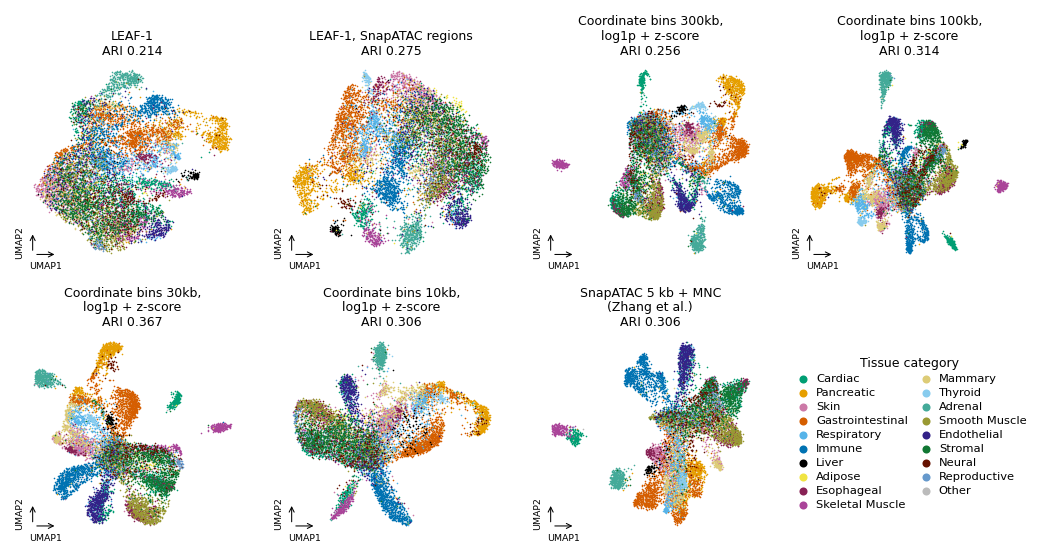

saved: scatac/output/scatac_atlas_fulldepth_umap_panel_by_category_supp.pdf
saved: scatac/output/scatac_atlas_fulldepth_umap_panel_by_category_supp.png
saved: scatac/output/scatac_atlas_fulldepth_umap_panel_by_category_supp.svg
saved: scatac/output/scatac_atlas_fulldepth_umap_panel_by_category_supp.tsv


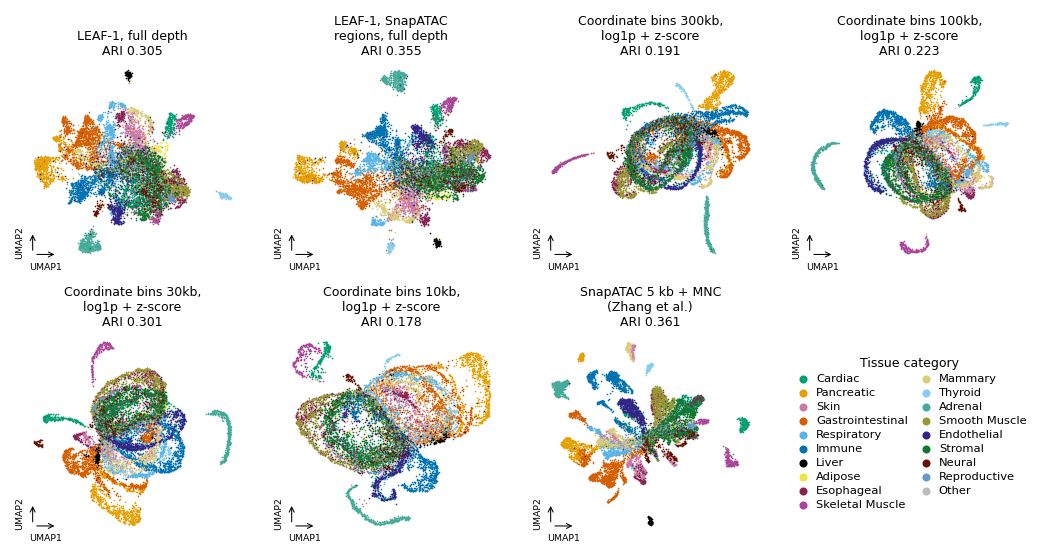

In [3]:
# ── UMAP grid, coloured by tissue category ────────────────────────────────────
# Colour identity is hard to read at 19 levels, so this panel is for global
# structure: does the representation put cells of the same tissue together at
# all, before any classifier is fit.
def umap_grid(stem, coords, scib):
    tags, titles, ari = scib.tag.tolist(), dict(zip(scib.tag, scib.title)), dict(zip(scib.tag, scib.ari))
    with plt.rc_context(PANEL_RC):
        fig, axes = plt.subplots(2, 4, figsize=(WIDTH, 3.7))
        axes = axes.ravel()
        for ax, tag in zip(axes, tags):
            pts = coords[coords.tag == tag]
            for lv, color in CATEGORY_COLORS.items():
                m = pts["category"].astype(str) == lv
                if m.any():
                    ax.scatter(pts.loc[m, "umap1"], pts.loc[m, "umap2"], s=0.6, c=[color],
                               label=lv, linewidth=0, rasterized=True)
            arrow_axes(ax)
            ax.set_title(f"{wrap_title(titles[tag])}\nARI {ari[tag]:.3f}", loc="center", pad=3)
        leg = axes[len(tags)]; leg.axis("off")
        handles, labels = axes[0].get_legend_handles_labels()
        leg.legend(handles, labels, loc="center", ncol=2, frameon=False, markerscale=5,
                   handletextpad=0.1, labelspacing=0.35, columnspacing=0.6, borderaxespad=0,
                   title="Tissue category", title_fontsize=6, fontsize=5.5)
        fig.tight_layout(h_pad=1.2, w_pad=0.8)
        savefig(fig, OUT, f"{stem}_umap_panel_by_category_supp", data=scib[["tag", "title", "ari"]])
        plt.show()


for stem, (coords, scib) in DATASETS.items():
    umap_grid(stem, coords, scib)

saved: scatac/output/scatac_atlas_scib_summary_supp.pdf
saved: scatac/output/scatac_atlas_scib_summary_supp.png
saved: scatac/output/scatac_atlas_scib_summary_supp.svg
saved: scatac/output/scatac_atlas_scib_summary_supp.tsv


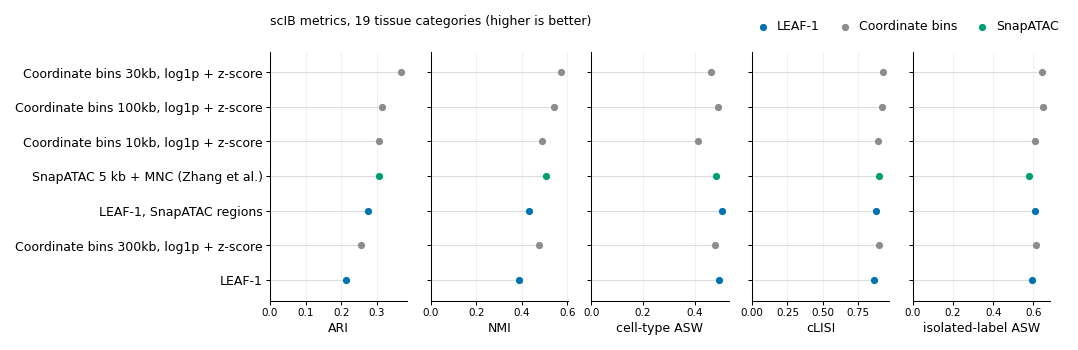

saved: scatac/output/scatac_atlas_fulldepth_scib_summary_supp.pdf
saved: scatac/output/scatac_atlas_fulldepth_scib_summary_supp.png
saved: scatac/output/scatac_atlas_fulldepth_scib_summary_supp.svg
saved: scatac/output/scatac_atlas_fulldepth_scib_summary_supp.tsv


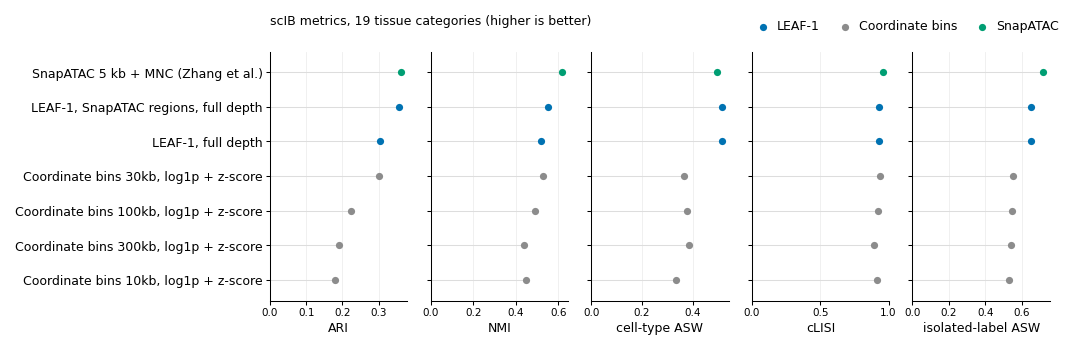

In [4]:
# ── scIB metrics across the same representations ─────────────────────────────
# Each metric lives on its own scale, so each gets its own column; rows share
# one order, by ARI. Dots rather than bars: these are point estimates, and a
# bar's filled area implies a magnitude from zero that ARI does not have.
def family(tag: str) -> str:
    if tag.startswith("snap"):
        return "SnapATAC"
    if tag.startswith("prob") or tag.startswith("leaf1"):
        return "LEAF-1"
    return "binning (norm)"


def scib_chart(stem, scib):
    df = scib.sort_values("ari").reset_index(drop=True)
    df["family"] = df["tag"].map(lambda t: FAMILY[family(t)][0])
    color = {name: col for name, col in FAMILY.values()}
    metrics = [(k, c) for k, c in METRICS if k not in DROP_METRICS and df[k].notna().any()]
    ypos = list(range(len(df)))
    with plt.rc_context(PANEL_RC):
        fig, axes = plt.subplots(1, len(metrics), figsize=(WIDTH, 2.3), sharey=True)
        for ax, (key, cap) in zip(axes, metrics):
            ax.hlines(ypos, 0, df[key], color="#DDDDDD", lw=0.5, zorder=1)
            for fam, sub in df.groupby("family"):
                ax.scatter(sub[key], sub.index, s=12, color=color[fam], label=fam, zorder=3, linewidth=0)
            ax.set_xlabel(cap, labelpad=2)
            ax.set_xlim(left=0)
            ax.xaxis.set_major_locator(MaxNLocator(nbins=4, steps=[1, 2, 2.5, 5, 10]))
            ax.spines[["top", "right"]].set_visible(False)
            ax.grid(axis="x", color="#EEEEEE", lw=0.4, zorder=0)
            ax.set_axisbelow(True)
            ax.tick_params(axis="both", length=2, pad=1.5)
        axes[0].set_yticks(ypos); axes[0].set_yticklabels(df["title"])
        axes[0].set_ylim(-0.6, len(df) - 0.4)
        by_label = dict(zip(*reversed(axes[0].get_legend_handles_labels())))
        l2 = [name for name, _ in FAMILY.values() if name in by_label]
        fig.tight_layout(w_pad=0.6, rect=(0, 0, 1, 0.9))
        fig.legend([by_label[n] for n in l2], l2, loc="lower right", bbox_to_anchor=(1.0, 0.9),
                   ncol=len(l2), frameon=False, handletextpad=0.1, columnspacing=1.0, borderaxespad=0)
        fig.text(axes[0].get_position().x0, 0.93,
                 f"scIB metrics, {df.iloc[0]['n_levels_label']} tissue categories (higher is better)",
                 ha="left", va="bottom", fontsize=6)
        savefig(fig, OUT, f"{stem}_scib_summary_supp",
                data=df[["tag", "title", "family"] + [k for k, _ in metrics]])
        plt.show()


for stem, (coords, scib) in DATASETS.items():
    scib_chart(stem, scib)